# Physical feedback scenarios already available in Cocoa

Gas cooling and outflows redistribute matter. A two-point correlation measures
pairs of density fluctuations; a three-point correlation also measures how
those fluctuations arrange into triangles. A model can therefore predict the
change in the power spectrum without predicting the change in the bispectrum.

This notebook follows the LSST Y1 and Roman feedback examples
(`projects/lsst_y1/EXAMPLE_EVALUATE3.ipynb` and
`projects/roman_real/EXAMPLE_EVALUATE3.ipynb`). It calls the same **bfmt
theory block**, compares all seven of its feedback scenarios, and propagates
their power responses into the DES Y3 $\xi_+$ and $\xi_-$ predictions. It also
calls both installed Burger2025 BACCO emulators, which predict a
power/bispectrum response pair from one feedback model. No curve in these
plots is the artificial teaching function of
[EXAMPLE_JOINT_FEEDBACK](EXAMPLE_JOINT_FEEDBACK.ipynb).

The example points illustrate model choices; they are not feedback fits to
DES. The two-point predictions are the 400 rows of the project's Cobaya likelihood
at the evaluate point of `EXAMPLE_EVALUATE1.yaml`: only the nonlinear matter
power changes, while the intrinsic-alignment model and the covariance stay
fixed. The notebook produces no posterior, no
Fisher forecast and no exact paper reproduction.

1. Run the existing theory block at the DES cosmology
2. Compare the physical power responses
3. Propagate them into the two-point observables
4. Evaluate the installed paired BACCO models
5. Check extrapolation and save the numerical evidence

The helpers live in
[the project wrapper](interface/cosmolike_des_3pcf_feedback_wrappers.py); every
prediction comes from the Cobaya likelihood with its
`external_baryon_suppression` key on. The
[project acknowledgements](README.md#acknowledgements) credit the fastnc and
Y3 three-point calculations of Sugiyama and Gomes.

**Model and data.** The settings come from the two YAML files the run reads:

| Choice | Value |
| --- | --- |
| Configuration | `EXAMPLE_EVALUATE1.yaml` on `data/des_y3_xi1.dataset`, which cuts the Map3 rows |
| Scenario catalog | `configs/feedback_scenarios.yaml`: three SP(k) relations, BCEmu, FLAMINGO, BACCO, BCemu2025 |
| Cosmology point | the yaml's evaluate point, with $\Omega_b=0.0463$ and $\sum m_\nu=0.06\,\mathrm{eV}$ |
| Data vector | 400 two-point rows; the figures show source pair (1,1) |
| Displayed scales | $0.05 \le k \le 8\,h/\mathrm{Mpc}$ at $z=0$ and $z=1$ |
| Outputs | figures in `chains/feedback_scenarios/`; arrays in `chains/feedback_scenarios.npz` |
| Threads | one worker each for BLAS, OpenMP and the JAX/TensorFlow emulator calls, on CPU |

Words used throughout:

- **DMO**, dark-matter-only: the gravity-only reference simulation or model; a
  feedback **response** is the ratio
  $R_P(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$.
- The **bfmt theory block** is Cocoa's Cobaya component for baryonic feedback:
  a block that computes the power response other components request.
- An **emulator** is an interpolator trained on simulations, with a finite
  parameter and scale range; **SP(k)** instead maps a halo's baryon fraction
  to the power suppression.
- **BCM**, the baryonic correction model, moves matter around halos with five
  parameters; the Burger2025 BACCO pair predicts its power and bispectrum
  responses from the same parameters.
- **Cold matter** means cold dark matter plus baryons, without the massive
  neutrinos that total matter includes.
- **NLA**, the nonlinear-alignment model: the intrinsic-alignment model of
  `EXAMPLE_EVALUATE1.yaml`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
# BACCO uses JAX for these small preparation calls; no GPU is requested.
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
from cobaya.yaml import yaml_load_file
import cosmolike_des_3pcf_feedback_wrappers as feedback

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. Run the existing theory block at the DES cosmology

A Cobaya theory block is a component that computes a requested quantity. Here
CAMB brings the expansion history and bfmt the response
$R_P(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$, whose denominator is
the model's gravity-only reference. The likelihood requests $k$ in
$1/\mathrm{Mpc}$ as bfmt expects and reads the response at $hk$ for its
$h/\mathrm{Mpc}$ tables; CAMB, BiHalofit and bfmt run in the same Cobaya model.

The [scenario catalog](configs/feedback_scenarios.yaml) copies the LSST/Roman
feedback points: three SP(k) halo-baryon-fraction relations, BCEmu, FLAMINGO,
BACCO and BCemu2025. BACCO works at this DES point because $\Omega_b=0.0463$
sits inside its training box, while the LSST example's $\Omega_b=0.04$ fell
just below it. The models need not produce the same gas distribution or
suppression: they span modeling choices, not a common parameter prior.

The wrapper builds one Cobaya model per scenario, evaluates the gravity-only
model again afterward, and requires exactly its original two-point rows. BLAS and
OpenMP use one worker for this example. The notebook needs the installed
emulators and installs nothing itself; Cocoa's
documented keys (`external_modules/code/baryon_suppression/README.md`) set up
missing models. A notebook run recalculates the outputs rather than silently
reading a cache.

In [3]:
# The numbered example EXAMPLE_EVALUATE1.yaml supplies the cosmology, the
# alignment model and the theory blocks. Its paths are relative to the Cocoa
# folder, hence the change of working directory. point = the parameter values
# Cobaya's evaluate sampler would run (the yaml's override block).
os.chdir(PROJECT.parents[1])
information = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE1.yaml"))
point = dict(information["sampler"]["evaluate"]["override"])
information.pop("sampler")
information.pop("output", None)

# One Cobaya model per catalog scenario: the bfmt block plus the likelihood key
# external_baryon_suppression, on the xi-only dataset (the likelihood refuses
# Map3 rows for a power-only model); a gravity-only model is the reference.
result = feedback.run_scenarios(
    information=information,
    point=point,
    catalog_path=PROJECT / "configs/feedback_scenarios.yaml",
)
print("Exact DMO restoration:", result["record"]["restoration_exact"])
output = PROJECT / "chains/feedback_scenarios"
output.mkdir(parents=True, exist_ok=True)

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[bfmt] BaryonSuppression.must_provide: baryon_suppression requested; n_z=125 [0.000, 3.100], n_k=256 [1.000e-05, 1.000e+03]


[bfmt] BaryonSuppression.must_provide: baryon_suppression requested; n_z=125 [0.000, 3.100], n_k=256 [1.000e-05, 1.000e+03]


[des_3pcf.joint_shear] Average evaluation time for des_3pcf.joint_shear: 1.24295 s  (1 evaluations)


[camb.transfers] Average evaluation time for camb.transfers: 1.64306 s  (1 evaluations)


... (65 outputs left out)

[camb.transfers] Average evaluation time for camb.transfers: 1.54621 s  (1 evaluations)


[camb] Average evaluation time for camb: 0.214935 s  (1 evaluations)


[bihalofit] Average evaluation time for bihalofit: 0.0130729 s  (1 evaluations)


Exact DMO restoration: True


## 2. Compare the physical power responses

The vertical axis shows $100(R_P-1)$: a value of $-10$ means ten percent less
power than the gravity-only reference. Two redshifts show how the same model
changes as structures evolve. SP(k)'s three curves differ in the relation
between halo mass and kept baryon fraction, and the second figure compares
four emulator families at their stated example points.

The figures show $0.05\lesssim k\lesssim8\,h/\mathrm{Mpc}$, which is not a
shared calibration interval for every curve: SP(k) applies its low-redshift
clamp below $z=0.125$, each model keeps its own Fourier boundaries and
interpolation inside bfmt, and above each model's maximum redshift the chosen
policy returns unity. The full projection table extends to
$1000\,h/\mathrm{Mpc}$, where several curves are extrapolations; section 5
tests one consequence of that extension rather than treating it as calibrated
gas physics.

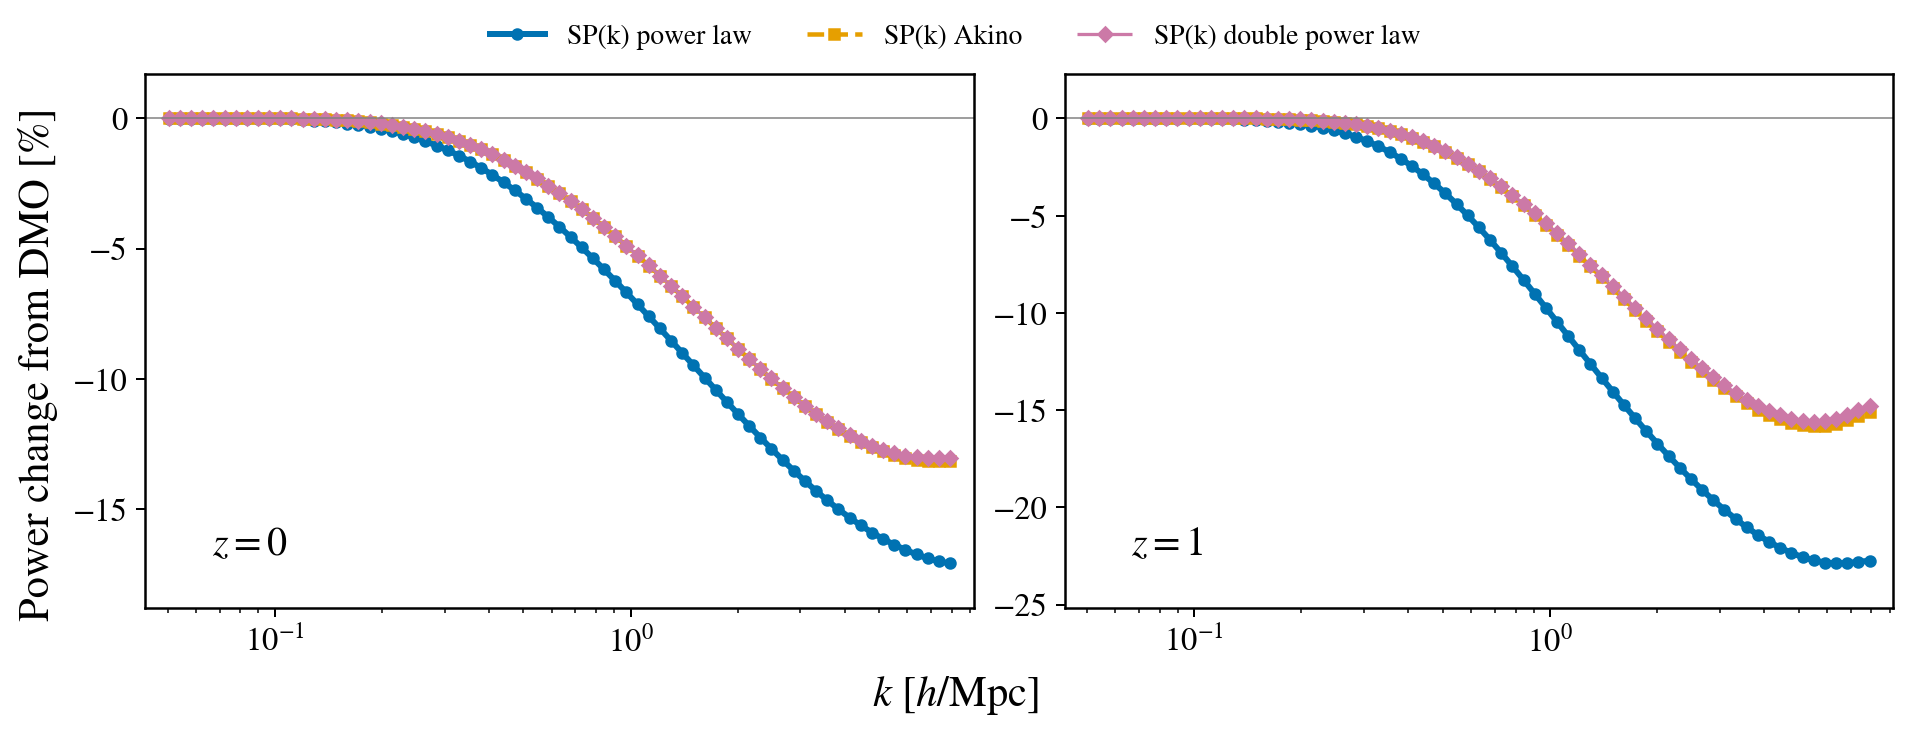

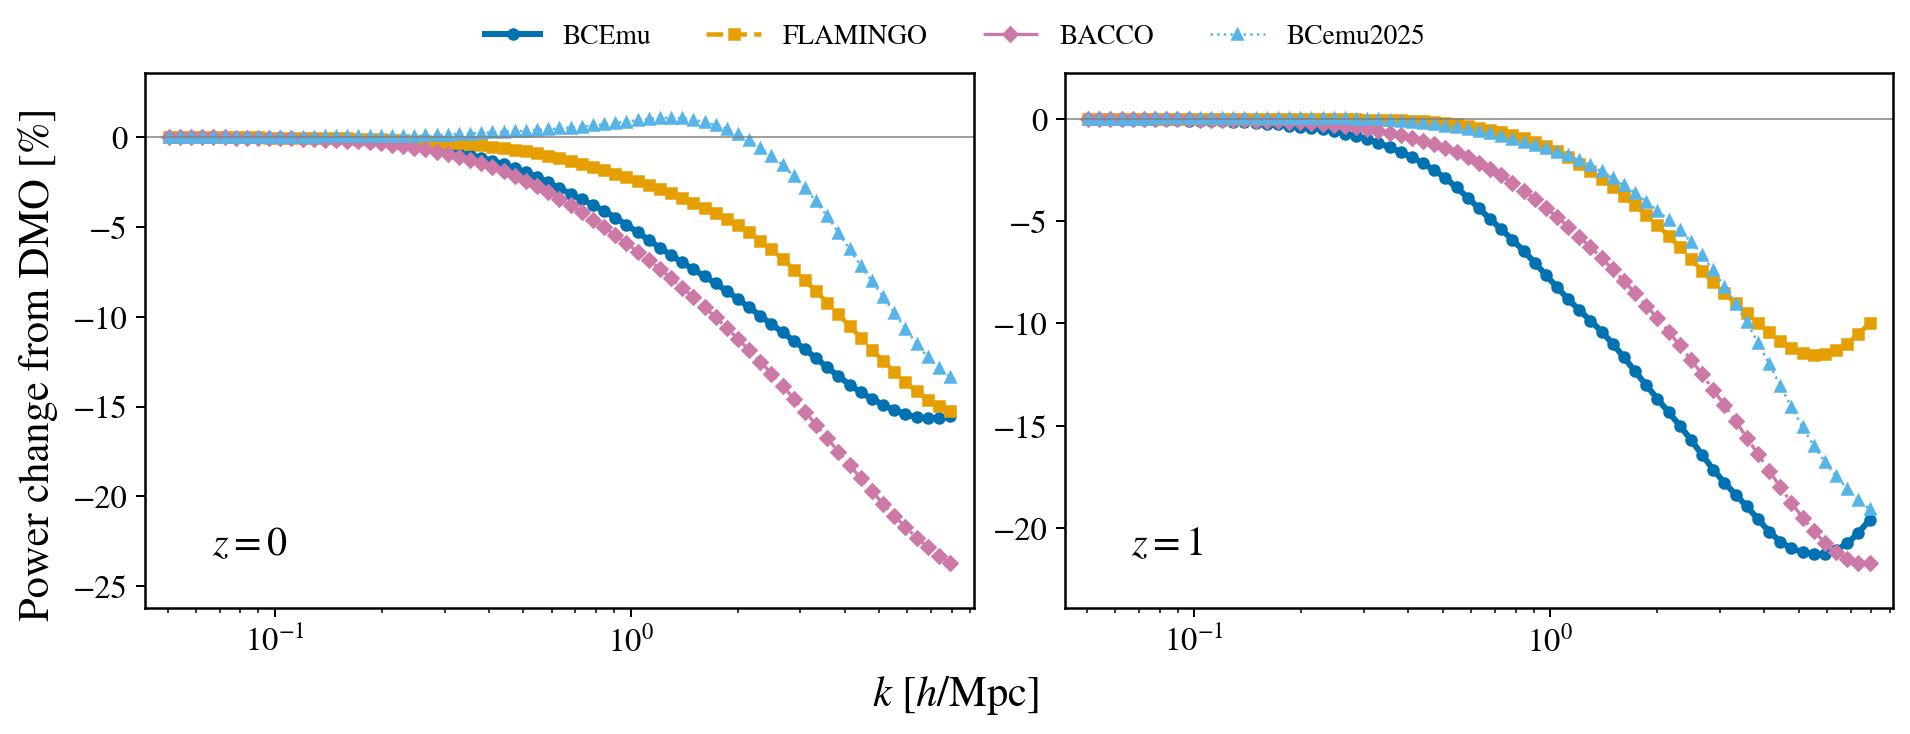

In [4]:
selected_k = (result["k"] >= 0.05) & (result["k"] <= 8.0)
redshift_indices = [int(np.argmin(np.abs(result["z"] - value))) for value in (0., 1.)]
np.testing.assert_allclose(result["z"][redshift_indices], [0., 1.], atol=1.e-12)
for group, indices in (("spk", [0, 1, 2]), ("emulators", [3, 4, 5, 6])):
    curves = []
    for index in indices:
        values = result["responses"][index, redshift_indices][:, selected_k]
        curves.append((result["k"][selected_k], 100. * (values - 1.)))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[r"$z=0$", r"$z=1$"],
        coordinate_label=r"$k$ [$h/\mathrm{Mpc}$]",
        quantity_label="Power change from DMO [%]",
        legend=[result["names"][index] for index in indices],
        marker=["o", "s", "D", "^"], linewidth=[2.4, 1.8, 1.3, 1.0],
        linestyle=["-", "--", "-.", ":"], ncols=2,
        figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.08, 0.10), show=None,
    )
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / f"power_{group}.png", dpi=150, pad_inches=0.2)
    figure.savefig(output / f"power_{group}.pdf", pad_inches=0.2)
    plt.show()


## 3. Propagate them into the two-point observables

The likelihood multiplies the nonlinear matter table by $R_P(k,z)$ before the
ordinary CosmoLike projection. The figures show source-bin pair (1,1);
the calculation covers all 400 rows. $\xi_+$ and $\xi_-$ respond differently
because they weight the angular power differently: in the small-angle limit,
$\xi_+(\theta)=\int d\ell\,\ell(C_E+C_B)J_0(\ell\theta)/(2\pi)$ and
$\xi_-(\theta)=\int d\ell\,\ell(C_E-C_B)J_4(\ell\theta)/(2\pi)$, where
$C_E,C_B$ are the two shear-parity power spectra and $J_0,J_4$ are Bessel
functions with different oscillatory weights. The same small-scale power
change can therefore produce different angular responses. A fixed-cosmology
change is not a parameter constraint: a fit must also vary cosmology and
nuisance parameters, apply the intended cuts, and use their covariance.

For BACCO, $R_P$ describes cold matter, meaning cold dark matter (CDM) plus
baryons. The existing Cocoa two-point prescription applies this ratio to the
total nonlinear power, which also contains the massive neutrinos of this DES
point ($\sum m_\nu=0.06\,\mathrm{eV}$). The notebook keeps that prescription
and labels it an approximation; displaying these curves does not establish its
validity. The six power-only models get no manufactured Map3 curve.

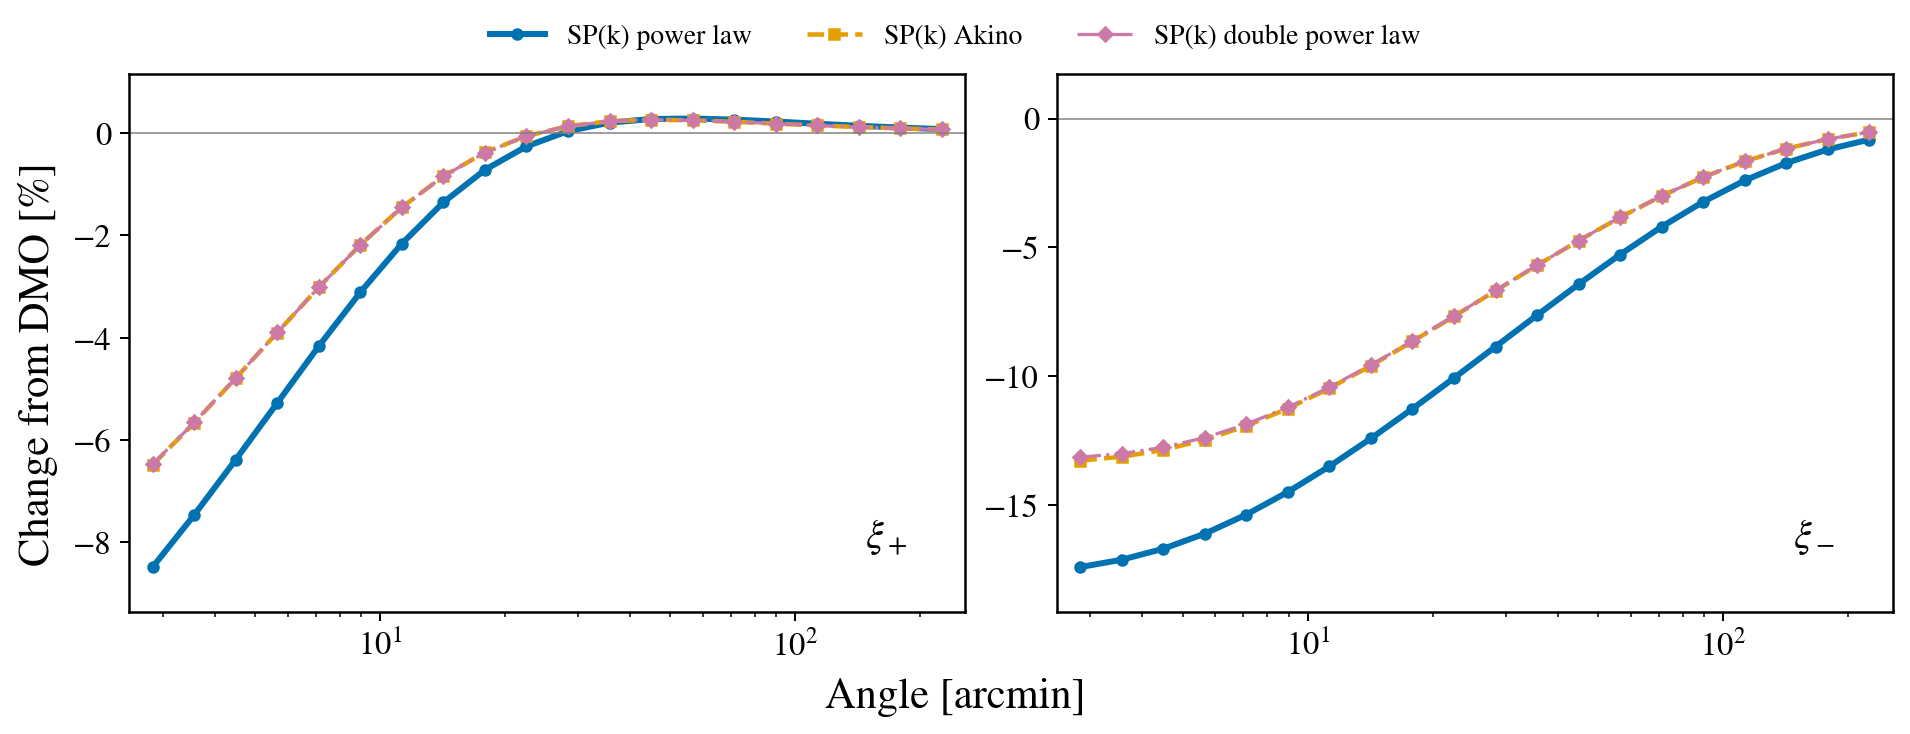

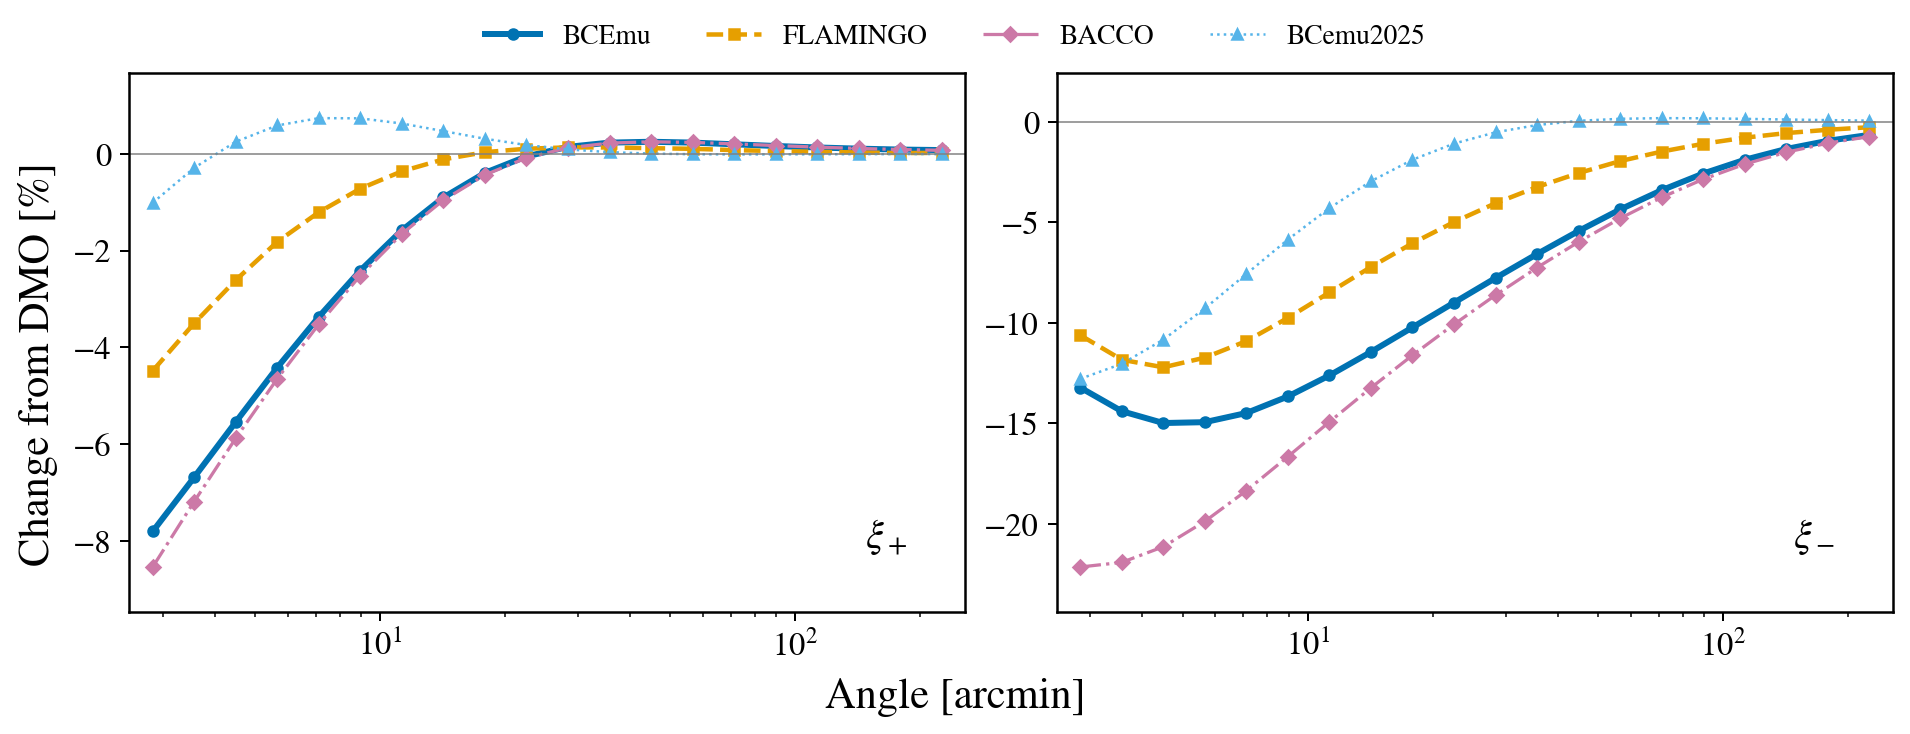

In [5]:
rows = result["rows"]
selected_rows = []
for kind in ("xip", "xim"):
    selected_rows.append(np.flatnonzero(
        (rows.kind == kind) & (rows.bins[:, 0] == 0) & (rows.bins[:, 1] == 0)
    ))
angles = rows.angles[selected_rows[0], 2] * 180. * 60. / np.pi
for group, indices in (("spk", [0, 1, 2]), ("emulators", [3, 4, 5, 6])):
    curves = []
    for index in indices:
        values = []
        for chosen in selected_rows:
            values.append(100. * (
                result["means"][index, chosen] / result["reference"][chosen] - 1.
            ))
        curves.append((angles, np.asarray(values)))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[r"$\xi_+$", r"$\xi_-$"],
        coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
        legend=[result["names"][index] for index in indices],
        marker=["o", "s", "D", "^"], linewidth=[2.4, 1.8, 1.3, 1.0],
        linestyle=["-", "--", "-.", ":"], ncols=2,
        figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.88, 0.12), show=None,
    )
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / f"xi_{group}.png", dpi=150, pad_inches=0.2)
    figure.savefig(output / f"xi_{group}.pdf", pad_inches=0.2)
    plt.show()


## 4. Evaluate the installed paired BACCO models

Burger et al. (arXiv:2506.18974) train a power response and a separate
bispectrum response from the same baryonic correction model, and the installed
BACCO package contains both, although bfmt exposes only power. The next cell
uses identical cold-matter cosmology and five feedback parameters for the
pair, and it obtains $\sigma_{8,cb}$ from the same BACCO amplitude conversion
bfmt uses rather than substituting the total-matter $\sigma_8$.

The baryonic correction model (BCM) moves matter around halos with five shared
parameters. All API inputs below are base-ten logarithms, even when a symbol
names a scale or slope rather than a mass:

| API coordinate | Physical role |
|---|---|
| `M_c` | Halo mass scale governing how much gas a halo keeps |
| `beta` | Mass dependence of the kept gas fraction |
| `eta` | Extent of ejected gas |
| `M1_z0_cen` | Mass scale in the central-galaxy stellar-mass relation |
| `theta_inn` | Inner gas-profile scale |

For example, `eta=-0.3` means an ejection coordinate of $10^{-0.3}$, not a
negative gas mass; the YAML lists the actual parameter numbers.

The triangles are equilateral $(k,k,k)$ and scalene $(0.6k,k,1.2k)$. Every
side stays within the installed side bounds, and highly squeezed and
degenerate triangles stay out on purpose. The adapter refuses out-of-range
inputs, checks the returned triangle order and counts, and records the
weight-file hashes, so an upstream float32 conversion or row removal cannot
silently change which triangles the curves represent. Staying inside the side
bounds is not an accuracy certificate for every triangle shape.

$R_B$ cannot in general follow from $R_P$, and the curves below impose no
$R_B=R_P^2$ or other power law: they demonstrate the available input. Both
responses describe cold matter rather than the full matter field when
neutrinos are massive, so a calibrated joint-lensing forecast still needs the
matter conversion or a documented approximation, a tested continuation outside
the training domain, and fresh responses whenever cosmology or feedback
parameters change. None of this requires the large covariance simulation
suite.

Sources: [Burger et al., arXiv:2506.18974](https://arxiv.org/abs/2506.18974),
[BACCO documentation](https://baccoemu.readthedocs.io/en/latest/).

Shared cold-matter coordinates: {'omega_cold': 0.28777669720619425, 'omega_baryon': 0.0463, 'sigma8_cold': 0.7898228168487549, 'M_c': 14.0, 'eta': -0.3, 'beta': -0.22, 'M1_z0_cen': 10.5, 'theta_inn': -0.86}


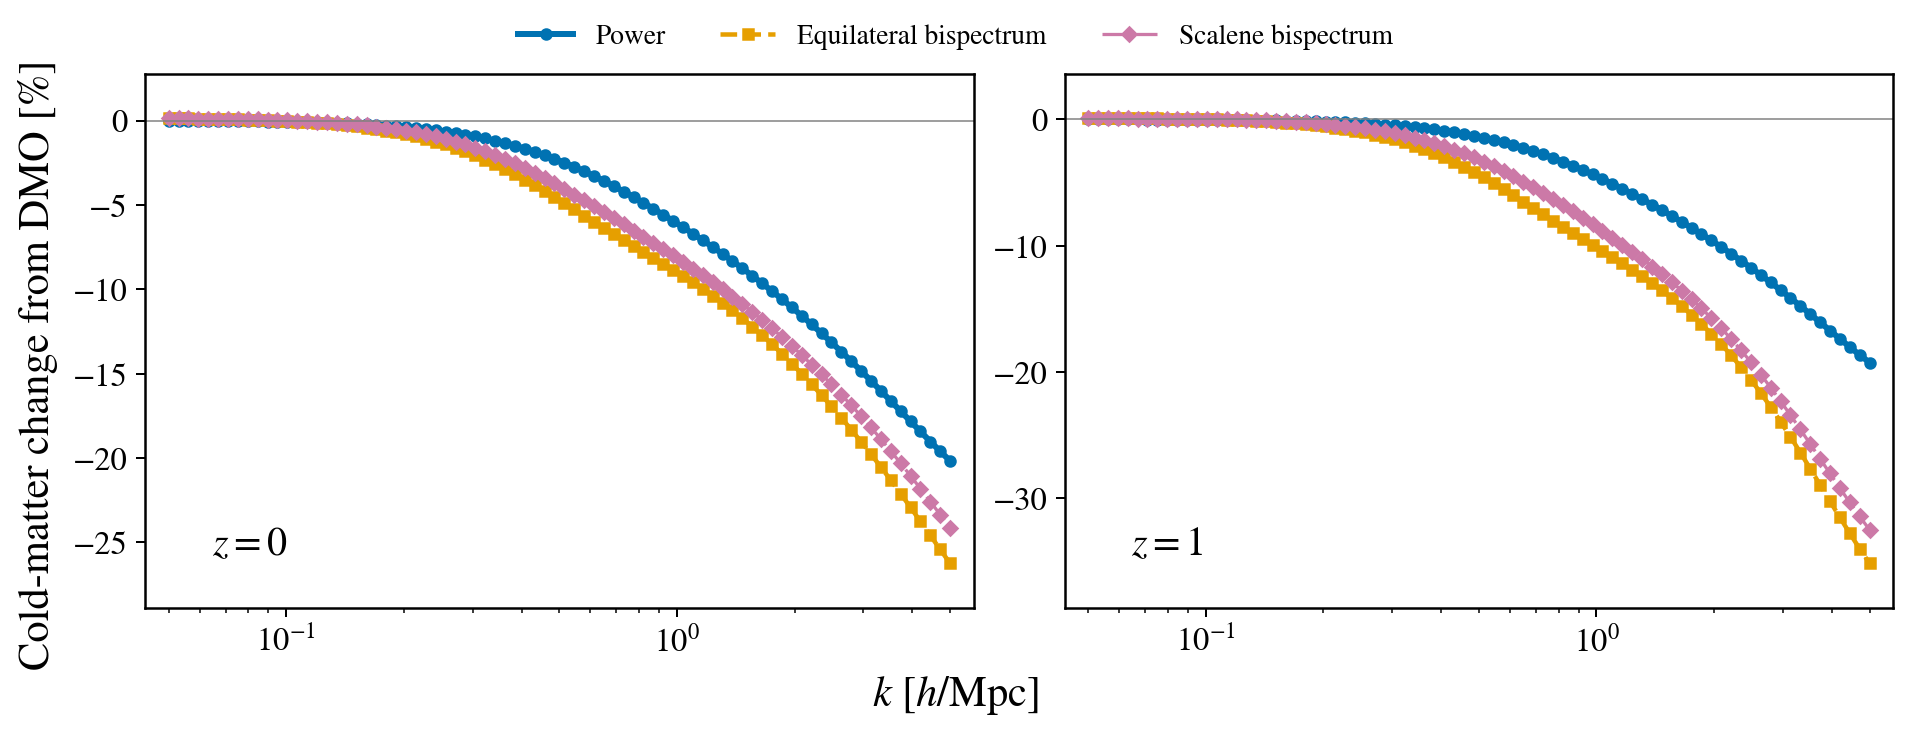

In [6]:
paired = feedback.bacco_diagnostic(records=result["records"])
print("Shared cold-matter coordinates:", paired["record"]["coordinates"])
curves = [(paired["k"], 100. * (paired["power"] - 1.))]
for shape in range(2):
    curves.append((paired["k"], 100. * (paired["bispectrum"][:, shape] - 1.)))
figure, axes = plots.plot_ia_components(
    components=curves, component_labels=[r"$z=0$", r"$z=1$"],
    coordinate_label=r"$k$ [$h/\mathrm{Mpc}$]",
    quantity_label="Cold-matter change from DMO [%]",
    legend=["Power", "Equilateral bispectrum", "Scalene bispectrum"],
    marker=["o", "s", "D"], linewidth=[2.4, 1.8, 1.3],
    linestyle=["-", "--", "-."], ncols=2, figsize=(10.5, 4.0),
    legendfontsize=11, bintextpos=(0.08, 0.10), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "bacco_paired.png", dpi=150, pad_inches=0.2)
figure.savefig(output / "bacco_paired.pdf", pad_inches=0.2)
plt.show()


## 5. Check extrapolation and save the numerical evidence

The run keeps the original bfmt output at every requested wavenumber. For one
diagnostic only, it replaces FLAMINGO's continuation above
$10\,h/\mathrm{Mpc}$ by the value at that pivot and recalculates the two-point
vector; the figure compares the two choices. A difference identifies
sensitivity to the assumed small-scale power, and holding the boundary
constant is itself an assumption, not a calibrated extension.

The NPZ records all 400 rows, all seven response tables, the paired BACCO
curves, the model points, the theory and weight hashes, and the exact DMO
restoration; its local numerical checks are not a survey-accuracy
certification. [EXAMPLE_JOINT_FEEDBACK](EXAMPLE_JOINT_FEEDBACK.ipynb)
exercises the generic native interface with an artificial response pair, while
this notebook provides the physical-model scenarios.

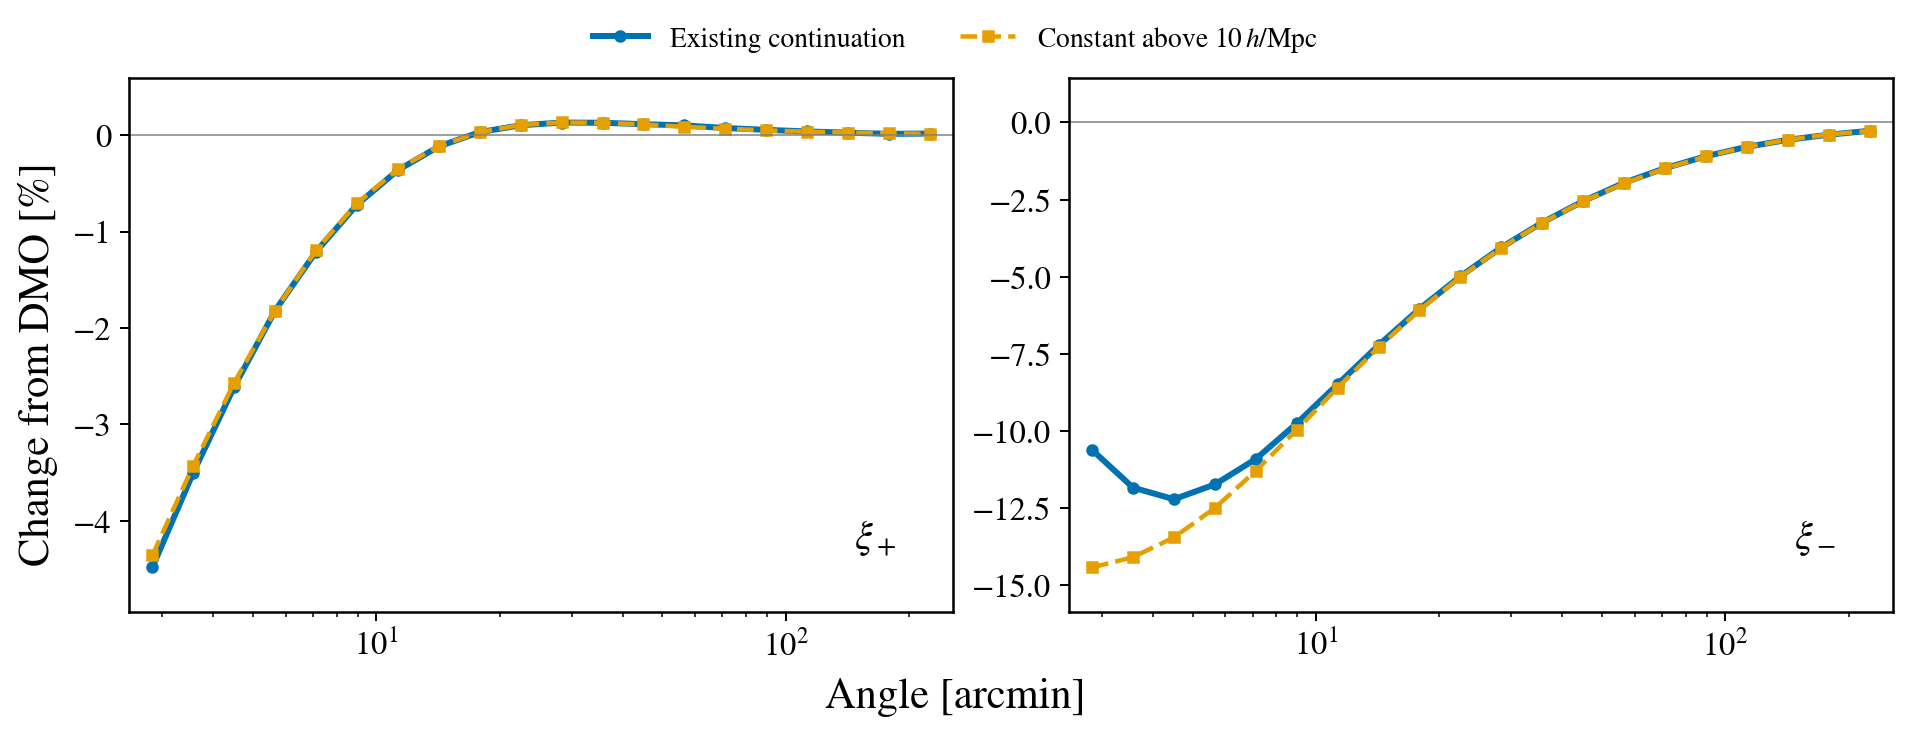

/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/chains/feedback_scenarios.npz


In [7]:
curves = []
flamingo = result["names"].index("FLAMINGO")
for mean in (result["means"][flamingo], result["tail_test"]):
    values = []
    for chosen in selected_rows:
        values.append(100. * (mean[chosen] / result["reference"][chosen] - 1.))
    curves.append((angles, np.asarray(values)))
figure, axes = plots.plot_ia_components(
    components=curves, component_labels=[r"$\xi_+$", r"$\xi_-$"],
    coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
    legend=["Existing continuation", r"Constant above $10\,h/\mathrm{Mpc}$"],
    marker=["o", "s"], linewidth=[2.4, 1.8], linestyle=["-", "--"],
    ncols=2, figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.88, 0.12), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "flamingo_tail.png", dpi=150, pad_inches=0.2)
figure.savefig(output / "flamingo_tail.pdf", pad_inches=0.2)
plt.show()
print(feedback.save_scenarios(
    result=result, paired=paired, destination=PROJECT / "chains/feedback_scenarios.npz",
))
